# Identity Matrices Example

This notebook demonstrates isometry pursuit on simulated data consisting of:
- One 10-dimensional identity matrix
- One 8-dimensional identity matrix (embedded in 10D)

Both matrices are embedded in 10-dimensional space, and we run isometry pursuit to see which columns are selected.


In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.exec.generate_orthogonal_data import generate_orthogonal_data

np.random.seed(1234)

# Generate data: one 10D identity and one 8D identity embedded in 10D
# matrix_specs: [(10, 1), (8, 1)] means 1 matrix of dimension 10 and 1 matrix of dimension 8
# embedding_dim=10 embeds both in 10-dimensional space
data_tensor, metadata = generate_orthogonal_data(
    output_dir="data/identity_example",
    matrix_specs=[(10, 1), (9, 10)],
    n_replicates=1,
    embedding_dim=10,
    noise_level=0.0,
    seed=1234
)

print(f"Data tensor shape: {data_tensor.shape}")
print(f"Metadata: {metadata}")

# Extract the first (and only) replicate as our data matrix X
# Shape: (D, n_samples) = (10, 18) - 10 columns from 10D identity + 8 columns from 8D identity
X = data_tensor[0, :, :]
print(f"\nData matrix X shape: {X.shape}")

# Run isometry pursuit on the data
result = isometry_pursuit(X, power=1.0)

beta = result["beta"]
selected_indices = result["basis_pursuit_indices"]

# Analyze which columns were selected
print("Analysis of selected columns:")
print(f"\nSelected indices: {selected_indices}")

# Check which come from the 10D identity (indices 0-9)
from_10d = [idx for idx in selected_indices if idx < 10]
# Check which come from the 8D identity (indices 10-17)
from_8d = [idx for idx in selected_indices if idx >= 10]

print(f"\nColumns from 10D identity (indices 0-9): {from_10d} ({len(from_10d)} columns)")
print(f"Columns from 8D identity (indices 10-17): {from_8d} ({len(from_8d)} columns)")

# Check if we got exactly 10 columns (the dimension)
print(f"\nExpected: 10 columns (since D=10)")
print(f"Actual: {len(selected_indices)} columns")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Generating orthogonal matrices...
Generating 1 10-dimensional orthogonal matrices...
  Matrix 1: shape (10, 10)
Generating 10 9-dimensional orthogonal matrices...
  Matrix 1: shape (10, 9)
  Matrix 2: shape (10, 9)
  Matrix 3: shape (10, 9)
  Matrix 4: shape (10, 9)
  Matrix 5: shape (10, 9)
  Matrix 6: shape (10, 9)
  Matrix 7: shape (10, 9)
  Matrix 8: shape (10, 9)
  Matrix 9: shape (10, 9)
  Matrix 10: shape (10, 9)
Total matrices: 11
Total samples: 100 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 10, 100)
Data tensor saved to data/identity_example/orthogonal_data_tensor.npy
Metadata saved to data/identity_example/orthogonal_data_metadata.json
Data tensor shape: (1, 10, 100)
Metadata: {'dataset_name': 'orthogonal_simulated', 'matrix_specs': [(10, 1), (9, 10)], 'n_matrices_total': 11, 'n_samples_total': 100, 'n_replicates': 1, 'dimension': 10, 'noise_level': 0.0, 'seed': 1234, 'data_file': 'data/identity_example/orthogonal_data_tensor.np

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


Analysis of selected columns:

Selected indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]

Columns from 10D identity (indices 0-9): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (10 columns)
Columns from 8D identity (indices 10-17): [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99] (90 columns)

Expected: 10 columns (since D=10)
Actual: 100 columns


In [62]:
# Assertion: Verify that the selected indices are exactly the 10D identity indices (0-9)
expected_10d_indices = set(range(10))
selected_set = set(selected_indices)

assert selected_set == expected_10d_indices, \
    f"Selected indices {sorted(selected_set)} do not match expected 10D indices {sorted(expected_10d_indices)}"

print("✓ Assertion passed: Selected indices are exactly the 10D identity indices [0-9]")
print(f"  Selected: {sorted(selected_set)}")
print(f"  Expected: {sorted(expected_10d_indices)}")


✓ Assertion passed: Selected indices are exactly the 10D identity indices [0-9]
  Selected: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  Expected: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [51]:
# Replicate Experiment

Now we run a systematic experiment varying:
- **Big D**: [2, 4, 8, 16] (embedding dimension)
- **Corrupting sizes**: For each D, smaller identity matrices of sizes:
  - D=2: [1]
  - D=4: [1, 2, 3]
  - D=8: [1, 4, 7]
  - D=16: [1, 8, 15]
- **Number of each corrupting matrix**: [2, 4, 8, 16]

For each configuration, we run 10 replicates and measure how often isometry pursuit correctly selects the full D×D identity matrix.


SyntaxError: invalid character '×' (U+00D7) (2960185140.py, line 12)

In [52]:
# Define experimental parameters
big_D_values = [2, 4, 8, 16]
corrupting_sizes = {
    2: [1],
    4: [1, 2, 3],
    8: [1, 4, 7],
    16: [1, 8, 15]
}
num_corrupting_values = [2, 4, 8, 16]
n_replicates = 10

print("Experimental Design:")
print(f"Big D values: {big_D_values}")
print(f"Number of corrupting matrices: {num_corrupting_values}")
print(f"Replicates per configuration: {n_replicates}")
print(f"\nCorrupting sizes for each D:")
for D in big_D_values:
    print(f"  D={D}: {corrupting_sizes[D]}")

total_configs = len(big_D_values) * len(num_corrupting_values)
total_runs = total_configs * n_replicates
print(f"\nTotal configurations: {total_configs}")
print(f"Total runs: {total_runs}")


Experimental Design:
Big D values: [2, 4, 8, 16]
Number of corrupting matrices: [2, 4, 8, 16]
Replicates per configuration: 10

Corrupting sizes for each D:
  D=2: [1]
  D=4: [1, 2, 3]
  D=8: [1, 4, 7]
  D=16: [1, 8, 15]

Total configurations: 16
Total runs: 160


In [53]:
# Run replicate experiment
import pandas as pd
from tqdm import tqdm

results = []

for D in tqdm(big_D_values, desc="Big D"):
    corrupting_dims = corrupting_sizes[D]
    
    for num_corrupting in tqdm(num_corrupting_values, desc=f"D={D}, num_corrupting", leave=False):
        # Build matrix_specs: 1 full D×D identity + num_corrupting copies of each corrupting size
        matrix_specs = [(D, 1)]  # 1 full D×D identity
        for small_dim in corrupting_dims:
            matrix_specs.append((small_dim, num_corrupting))
        
        # Calculate total number of columns
        total_cols = D + sum(small_dim * num_corrupting for small_dim in corrupting_dims)
        
        successes = 0
        for rep in range(n_replicates):
            # Generate data
            data_tensor, _ = generate_orthogonal_data(
                output_dir=f"data/identity_example_D{D}_nc{num_corrupting}_rep{rep}",
                matrix_specs=matrix_specs,
                n_replicates=1,
                embedding_dim=D,
                noise_level=0.0,
                seed=1234 + rep  # Different seed for each replicate
            )
            
            X = data_tensor[0, :, :]
            
            # Run isometry pursuit
            result = isometry_pursuit(X, power=1.0)
            selected_indices = result["basis_pursuit_indices"]
            
            # Check if correct: selected indices should be [0, 1, ..., D-1]
            expected_indices = set(range(D))
            selected_set = set(selected_indices)
            is_correct = (selected_set == expected_indices)
            
            if is_correct:
                successes += 1
            
            # Store result
            results.append({
                'D': D,
                'num_corrupting': num_corrupting,
                'corrupting_sizes': str(corrupting_dims),
                'replicate': rep,
                'success': is_correct,
                'num_selected': len(selected_indices),
                'selected_indices': str(sorted(selected_set))
            })
        
        success_rate = successes / n_replicates
        print(f"D={D}, num_corrupting={num_corrupting}: {successes}/{n_replicates} successes ({success_rate:.1%})")

# Convert to DataFrame
results_df = pd.DataFrame(results)
print(f"\nExperiment complete! Total runs: {len(results_df)}")


Big D:   0%|                                                                                        | 0/4 [00:00<?, ?it/s]/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/pytho

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 2 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
  Matrix 2: shape (2, 1)
Total matrices: 3
Total samples: 4 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 4)
Data tensor saved to data/identity_example_D2_nc2_rep0/orthogonal_data_tensor.npy
Metadata saved to data/identity_example_D2_nc2_rep0/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 2 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
  Matrix 2: shape (2, 1)
Total matrices: 3
Total samples: 4 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 4)
Data tensor saved to data/identity_example_D2_nc2_rep1/orthogonal_data_tensor.npy
Metadata saved to data/identity_example_D2_nc2_rep1/orthogonal_data_meta

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 2 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
  Matrix 2: shape (2, 1)
Total matrices: 3
Total samples: 4 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 4)
Data tensor saved to data/identity_example_D2_nc2_rep6/orthogonal_data_tensor.npy
Metadata saved to data/identity_example_D2_nc2_rep6/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 2 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
  Matrix 2: shape (2, 1)
Total matrices: 3
Total samples: 4 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 4)
Data tensor saved to data/identity_example_D2_nc2_rep7/orthogonal_data_tensor.npy
Metadata saved to data/identity_example_D2_nc2_rep7/orthogonal_data_meta

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

...

Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 16 1-dimensional orthogonal matrices...
  Matrix 1: shape (16, 1)
  Matrix 2: shape (16, 1)
  Matrix 3: shape (16, 1)
  Matrix 4: shape (16, 1)
  Matrix 5: shape (16, 1)
  Matrix 6: shape (16, 1)
  Matrix 7: shape (16, 1)
  Matrix 8: shape (16, 1)
  Matrix 9: shape (16, 1)
  Matrix 10: shape (16, 1)
  Matrix 11: shape (16, 1)
  Matrix 12: shape (16, 1)
  Matrix 13: shape (16, 1)
  Matrix 14: shape (16, 1)
  Matrix 15: shape (16, 1)
  Matrix 16: shape (16, 1)
Generating 16 8-dimensional orthogonal matrices...
  Matrix 1: shape (16, 8)
  Matrix 2: shape (16, 8)
  Matrix 3: shape (16, 8)
  Matrix 4: shape (16, 8)
  Matrix 5: shape (16, 8)
  Matrix 6: shape (16, 8)
  Matrix 7: shape (16, 8)
  Matrix 8: shape (16, 8)
  Matrix 9: shape (16, 8)
  Matrix 10: shape (16, 8)
  Matrix 11: shape (16, 8)
  Matrix 12: shape (16, 8)
  Matrix 13: shape (16, 8)
  Matrix 14: shape (1

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: divide by zero encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: overflow encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: invalid value encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded


Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 16 1-dimensional orthogonal matrices...
  Matrix 1: shape (16, 1)
  Matrix 2: shape (16, 1)
  Matrix 3: shape (16, 1)
  Matrix 4: shape (16, 1)
  Matrix 5: shape (16, 1)
  Matrix 6: shape (16, 1)
  Matrix 7: shape (16, 1)
  Matrix 8: shape (16, 1)
  Matrix 9: shape (16, 1)
  Matrix 10: shape (16, 1)
  Matrix 11: shape (16, 1)
  Matrix 12: shape (16, 1)
  Matrix 13: shape (16, 1)
  Matrix 14: shape (16, 1)
  Matrix 15: shape (16, 1)
  Matrix 16: shape (16, 1)
Generating 16 8-dimensional orthogonal matrices...
  Matrix 1: shape (16, 8)
  Matrix 2: shape (16, 8)
  Matrix 3: shape (16, 8)
  Matrix 4: shape (16, 8)
  Matrix 5: shape (16, 8)
  Matrix 6: shape (16, 8)
  Matrix 7: shape (16, 8)
  Matrix 8: shape (16, 8)
  Matrix 9: shape (16, 8)
  Matrix 10: shape (16, 8)
  Matrix 11: shape (16, 8)
  Matrix 12: shape (16, 8)
  Matrix 13: shape (16, 8)
  Matrix 14: shape (1

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
Big D: 100%|███████████████████████████████████████████████████████████████████████████████| 4/4 [30:05<00:00, 451.40s/it]

D=16, num_corrupting=16: 0/10 successes (0.0%)

Experiment complete! Total runs: 160


In [54]:
# Compute success rates by configuration
success_rates = results_df.groupby(['D', 'num_corrupting']).agg({
    'success': ['sum', 'count', 'mean']
}).reset_index()
success_rates.columns = ['D', 'num_corrupting', 'successes', 'total', 'success_rate']

print("Success Rates by Configuration:")
print(success_rates.to_string(index=False))


Success Rates by Configuration:
 D  num_corrupting  successes  total  success_rate
 2               2          6     10           0.6
 2               4          1     10           0.1
 2               8          0     10           0.0
 2              16          0     10           0.0
 4               2          3     10           0.3
 4               4          0     10           0.0
 4               8          0     10           0.0
 4              16          0     10           0.0
 8               2         10     10           1.0
 8               4          0     10           0.0
 8               8          0     10           0.0
 8              16          0     10           0.0
16               2         10     10           1.0
16               4         10     10           1.0
16               8          0     10           0.0
16              16          0     10           0.0


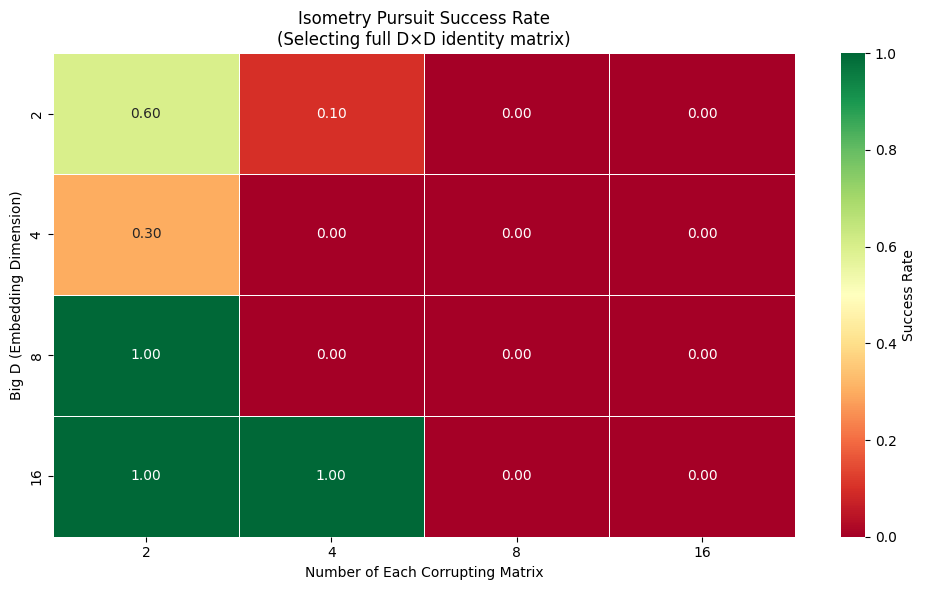

In [55]:
# Visualize results: Heatmap of success rates
import seaborn as sns

# Pivot for heatmap
heatmap_data = success_rates.pivot(index='D', columns='num_corrupting', values='success_rate')

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, 
            cbar_kws={'label': 'Success Rate'}, linewidths=0.5)
plt.title('Isometry Pursuit Success Rate\n(Selecting full D×D identity matrix)')
plt.xlabel('Number of Each Corrupting Matrix')
plt.ylabel('Big D (Embedding Dimension)')
plt.tight_layout()
plt.show()


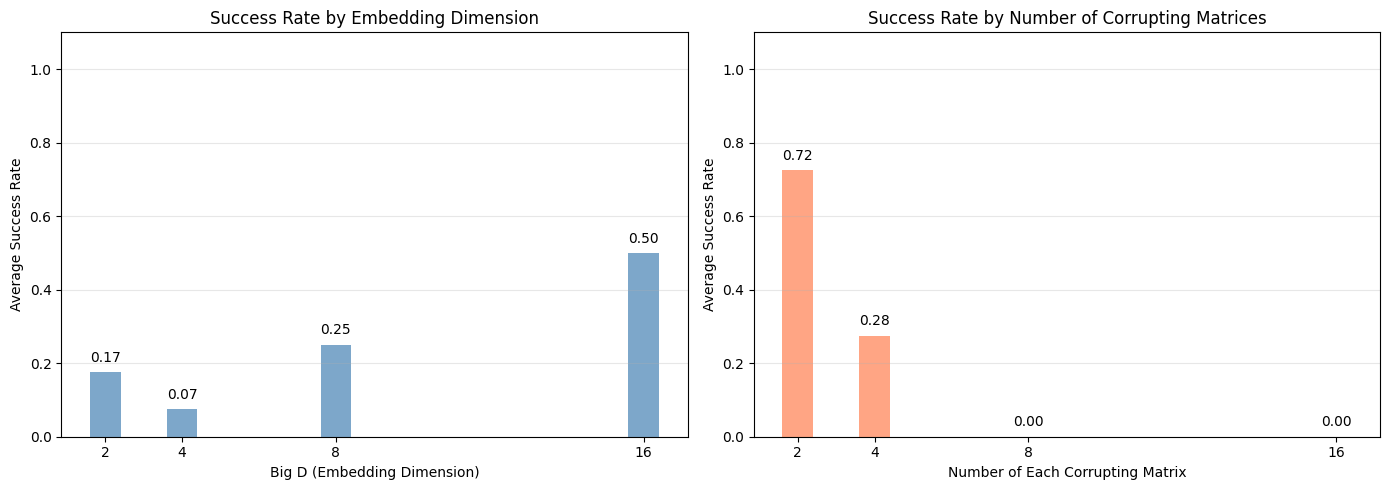

In [56]:
# Bar plot: Success rate by D
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Success rate by D (averaged over num_corrupting)
ax1 = axes[0]
by_D = success_rates.groupby('D')['success_rate'].mean().reset_index()
bars = ax1.bar(by_D['D'], by_D['success_rate'], color='steelblue', alpha=0.7)
ax1.set_xlabel('Big D (Embedding Dimension)')
ax1.set_ylabel('Average Success Rate')
ax1.set_title('Success Rate by Embedding Dimension')
ax1.set_ylim(0, 1.1)
ax1.set_xticks(by_D['D'])
ax1.grid(True, alpha=0.3, axis='y')
for i, (d, rate) in enumerate(zip(by_D['D'], by_D['success_rate'])):
    ax1.text(d, rate + 0.02, f'{rate:.2f}', ha='center', va='bottom')

# Plot 2: Success rate by num_corrupting (averaged over D)
ax2 = axes[1]
by_num = success_rates.groupby('num_corrupting')['success_rate'].mean().reset_index()
bars2 = ax2.bar(by_num['num_corrupting'], by_num['success_rate'], color='coral', alpha=0.7)
ax2.set_xlabel('Number of Each Corrupting Matrix')
ax2.set_ylabel('Average Success Rate')
ax2.set_title('Success Rate by Number of Corrupting Matrices')
ax2.set_ylim(0, 1.1)
ax2.set_xticks(by_num['num_corrupting'])
ax2.grid(True, alpha=0.3, axis='y')
for i, (nc, rate) in enumerate(zip(by_num['num_corrupting'], by_num['success_rate'])):
    ax2.text(nc, rate + 0.02, f'{rate:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()


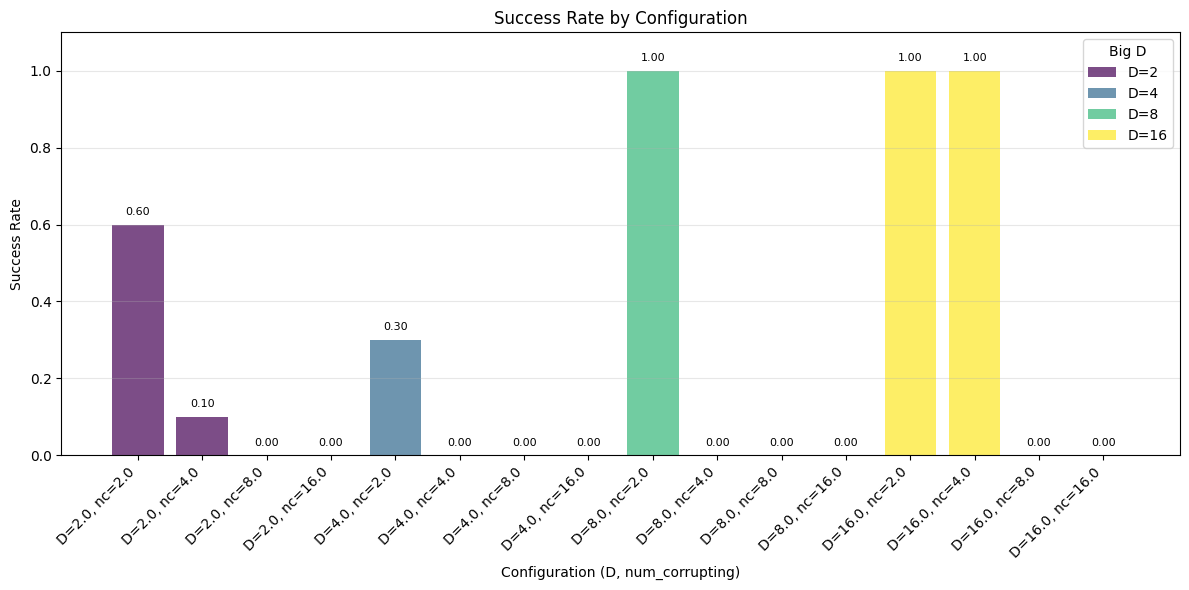

In [57]:
# Detailed breakdown: Success rate for each (D, num_corrupting) combination
fig, ax = plt.subplots(figsize=(12, 6))

x_pos = np.arange(len(success_rates))
colors = plt.cm.viridis(np.linspace(0, 1, len(big_D_values)))

# Group by D for different colors
for i, D in enumerate(big_D_values):
    mask = success_rates['D'] == D
    subset = success_rates[mask]
    x_subset = x_pos[mask]
    ax.bar(x_subset, subset['success_rate'], 
           label=f'D={D}', color=colors[i], alpha=0.7, width=0.8)

ax.set_xlabel('Configuration (D, num_corrupting)')
ax.set_ylabel('Success Rate')
ax.set_title('Success Rate by Configuration')
ax.set_ylim(0, 1.1)
ax.set_xticks(x_pos)
ax.set_xticklabels([f"D={row['D']}, nc={row['num_corrupting']}" 
                    for _, row in success_rates.iterrows()], 
                   rotation=45, ha='right')
ax.legend(title='Big D')
ax.grid(True, alpha=0.3, axis='y')

# Add value labels
for i, (_, row) in enumerate(success_rates.iterrows()):
    ax.text(i, row['success_rate'] + 0.02, f"{row['success_rate']:.2f}", 
            ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


In [58]:
# Summary statistics
print("Summary Statistics:")
print(f"\nOverall success rate: {results_df['success'].mean():.2%}")
print(f"\nSuccess rate by D:")
print(results_df.groupby('D')['success'].mean())
print(f"\nSuccess rate by num_corrupting:")
print(results_df.groupby('num_corrupting')['success'].mean())
print(f"\nConfigurations with 100% success:")
perfect = success_rates[success_rates['success_rate'] == 1.0]
print(perfect[['D', 'num_corrupting', 'success_rate']].to_string(index=False))
print(f"\nConfigurations with <100% success:")
imperfect = success_rates[success_rates['success_rate'] < 1.0]
if len(imperfect) > 0:
    print(imperfect[['D', 'num_corrupting', 'success_rate']].to_string(index=False))
else:
    print("  None - all configurations achieved 100% success!")


Summary Statistics:

Overall success rate: 25.00%

Success rate by D:
D
2     0.175
4     0.075
8     0.250
16    0.500
Name: success, dtype: float64

Success rate by num_corrupting:
num_corrupting
2     0.725
4     0.275
8     0.000
16    0.000
Name: success, dtype: float64

Configurations with 100% success:
 D  num_corrupting  success_rate
 8               2           1.0
16               2           1.0
16               4           1.0

Configurations with <100% success:
 D  num_corrupting  success_rate
 2               2           0.6
 2               4           0.1
 2               8           0.0
 2              16           0.0
 4               2           0.3
 4               4           0.0
 4               8           0.0
 4              16           0.0
 8               4           0.0
 8               8           0.0
 8              16           0.0
16               8           0.0
16              16           0.0
